
# Machine Failure Prediction using Machine Learning

## Project Overview
This project aims to predict machine failures using machine
operating parameters such as temperature, rotational speed,
torque, and tool wear.

Machine learning classification models will be developed to
identify potential machine failures and support predictive
maintenance in industrial environments.

## Objective
To build and evaluate machine learning models that predict
whether a machine is likely to fail based on its operating
conditions.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("ai4i2020.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Dataset Overview
In this section, we examine the dataset structure, dimensions,
data types, and missing values to understand the data before
performing preprocessing and model building.

In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (10000, 14)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [8]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [9]:
# Display descriptive statistics for numerical columns
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## Data Quality Check
In this section, we check for duplicate records to ensure
the dataset does not contain repeated observations.

In [10]:
# Count duplicate rows in the dataset
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Machine Failure Distribution
We analyze the distribution of machine failure cases to
understand the proportion of normal and failed machines.

In [11]:
# Count normal and failed machine records
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

## Machine Failure Visualization
Visualize the number of normal and failed machines using a bar chart.

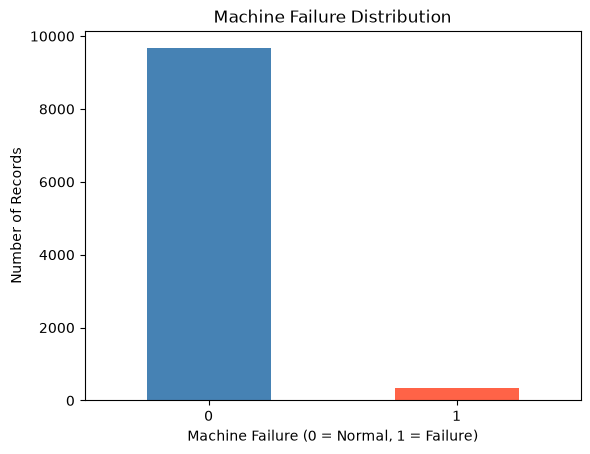

In [12]:
# Plot the distribution of machine failure classes
failure_counts = df["Machine failure"].value_counts().sort_index()

failure_counts.plot(kind="bar", color=["steelblue", "tomato"])

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [13]:
# Calculate the percentage of each machine failure category
failure_percentage = df["Machine failure"].value_counts(normalize=True) * 100

print(failure_percentage)

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


## Machine Failure Type Analysis
Analyze the different machine failure types to understand
which failure mechanisms occur most frequently.

In [14]:
# Count occurrences of each individual failure type
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df[failure_types].sum()

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

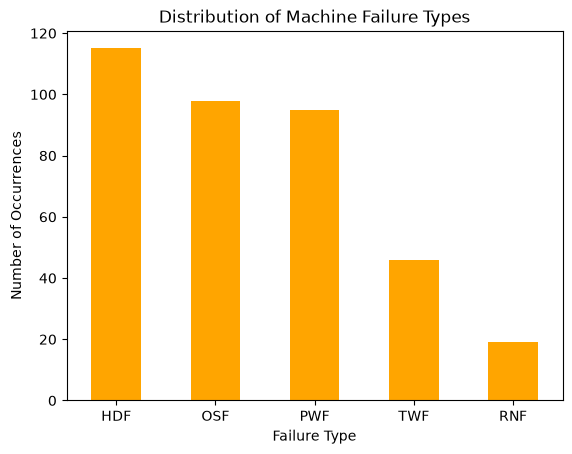

In [15]:
# Plot the frequency of individual machine failure types
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]
failure_counts = df[failure_types].sum()

failure_counts.sort_values(ascending=False).plot(
    kind="bar",
    color="orange"
)

plt.title("Distribution of Machine Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Occurrences")
plt.xticks(rotation=0)
plt.show()

## Numerical Feature Analysis
Analyze the distribution of numerical machine operating
parameters to understand their characteristics.

In [16]:
# Select numerical operating parameters
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Display summary statistics for these features
df[numerical_features].describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


## Numerical Feature Distribution
Visualize numerical feature distributions using histograms
to understand their spread and identify possible outliers.

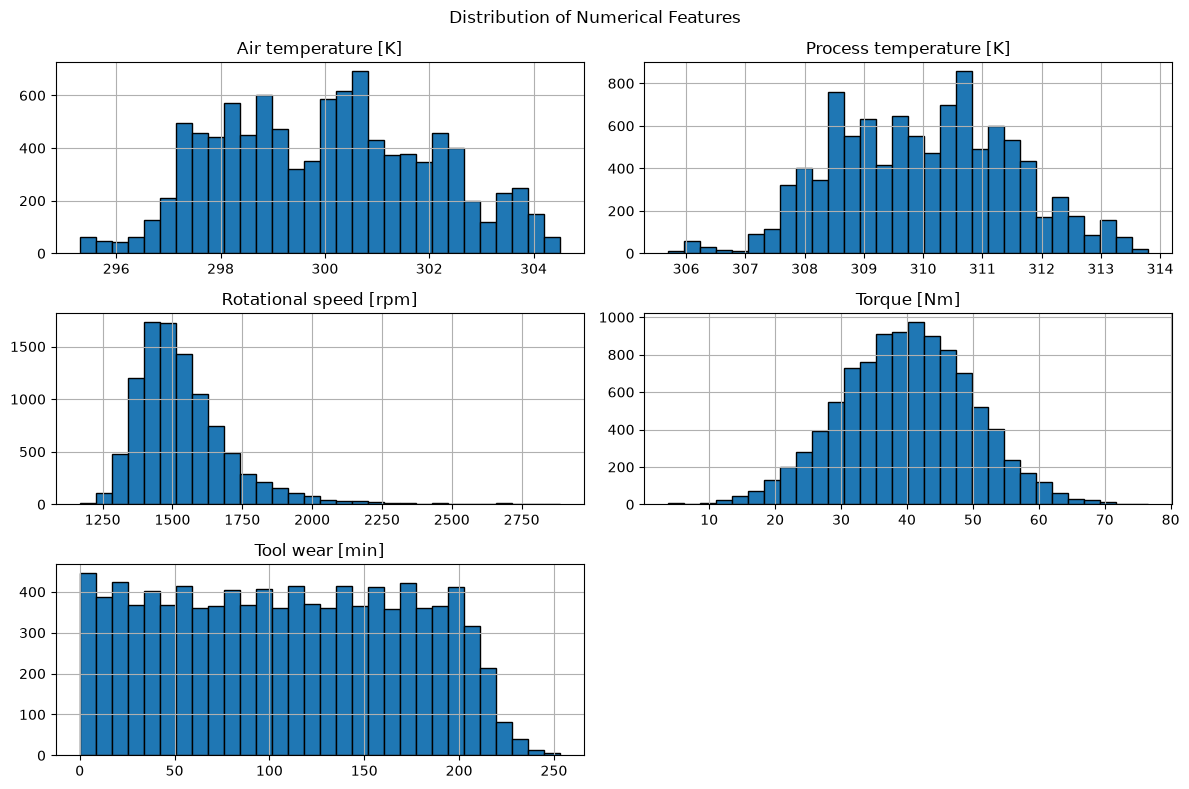

In [17]:
# Plot histograms for all numerical operating parameters
df[numerical_features].hist(figsize=(12, 8), bins=30, edgecolor="black")

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

## Correlation Analysis
Analyze correlations between numerical features to understand
relationships between machine operating parameters.

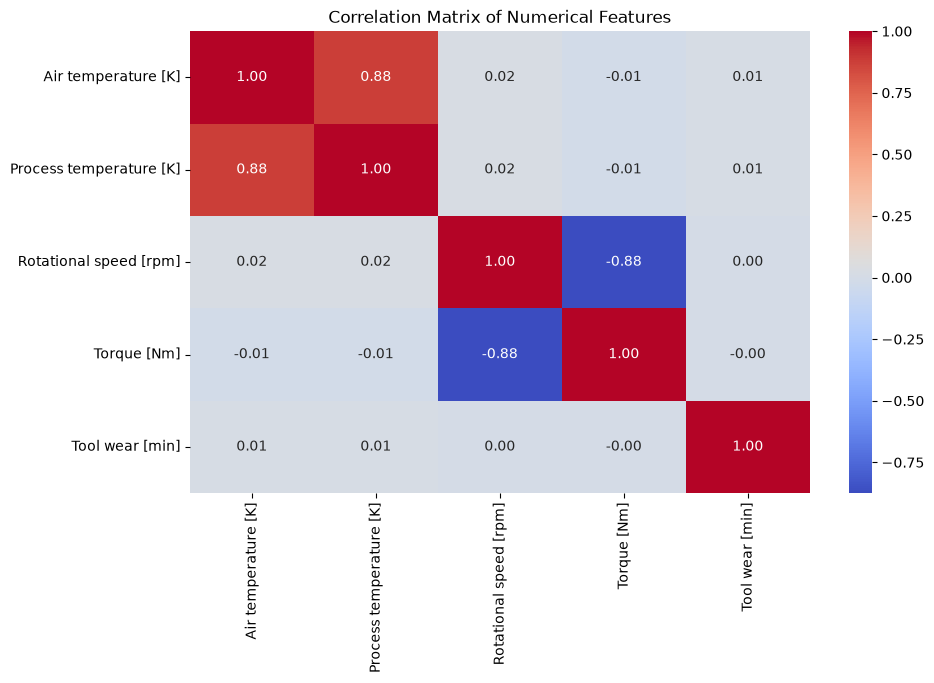

In [18]:
# Calculate correlation between numerical operating parameters
correlation = df[numerical_features].corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix of Numerical Features")
plt.show()

## Machine Failure vs Operating Parameters
Compare numerical operating parameters between normal and
failed machines to identify potential failure patterns.

In [19]:
# Compare average operating parameters for normal and failed machines
df.groupby("Machine failure")[numerical_features].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


## Operating Parameters by Machine Failure
Visualize differences in operating parameters between
normal and failed machines using boxplots.

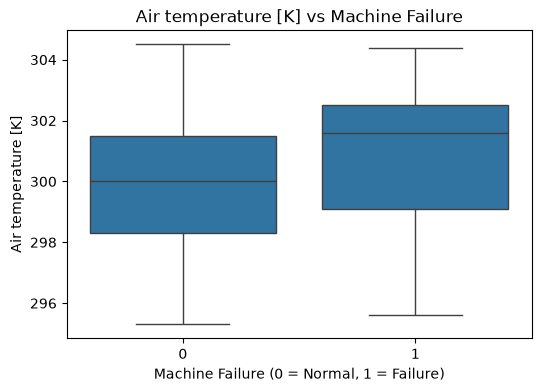

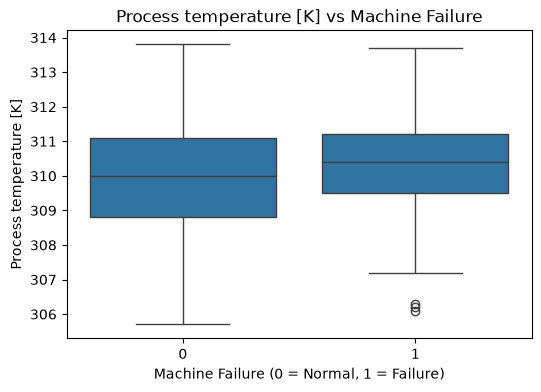

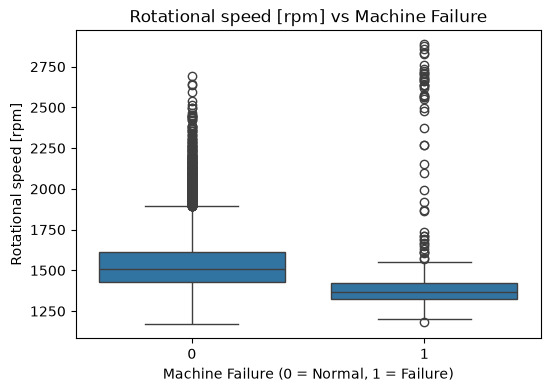

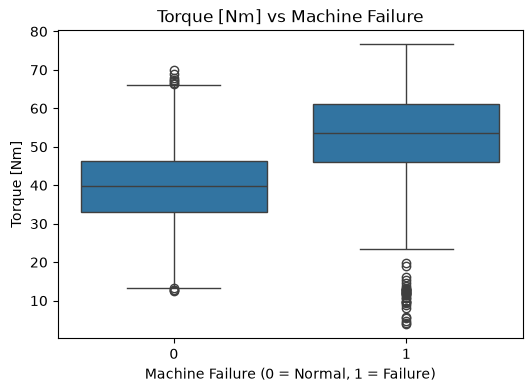

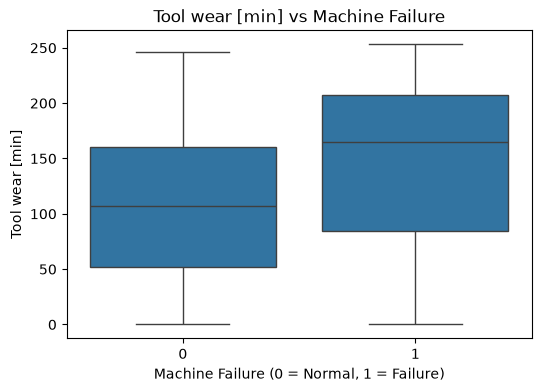

In [20]:
# Compare numerical features across machine failure categories
for feature in numerical_features:
    plt.figure(figsize=(6, 4))

    sns.boxplot(data=df, x="Machine failure", y=feature)

    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
    plt.ylabel(feature)
    plt.show()

## Product Type vs Machine Failure
Analyze machine failures across different product quality types.

In [21]:
# Count normal and failed machines for each product type
pd.crosstab(df["Type"], df["Machine failure"])

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


In [22]:
# Calculate machine failure percentage for each product type
failure_rate = pd.crosstab(
    df["Type"],
    df["Machine failure"],
    normalize="index"
) * 100

# Display only the failure percentage
failure_rate[1].rename("Failure Percentage")

Type
H    2.093719
L    3.916667
M    2.769436
Name: Failure Percentage, dtype: float64

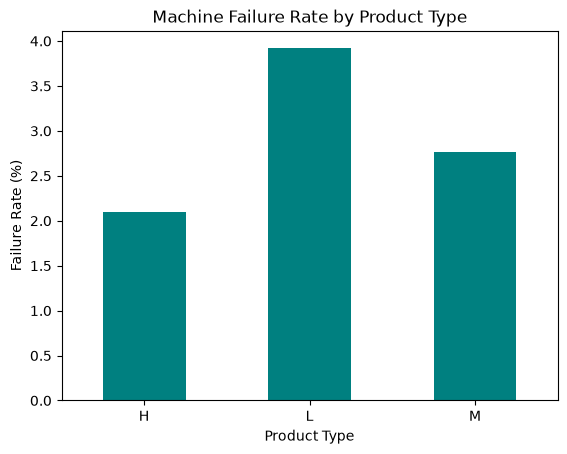

In [23]:
# Plot failure percentage for each product type
failure_rate[1].plot(kind="bar", color="teal")

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=0)
plt.show()

## Feature Correlation with Machine Failure
Analyze the correlation between numerical operating parameters
and the machine failure target.

In [24]:
# Calculate correlation between numerical features and machine failure
failure_correlation = df[numerical_features + ["Machine failure"]].corr()

# Display correlations with machine failure
failure_correlation["Machine failure"].sort_values(ascending=False)

Machine failure            1.000000
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64

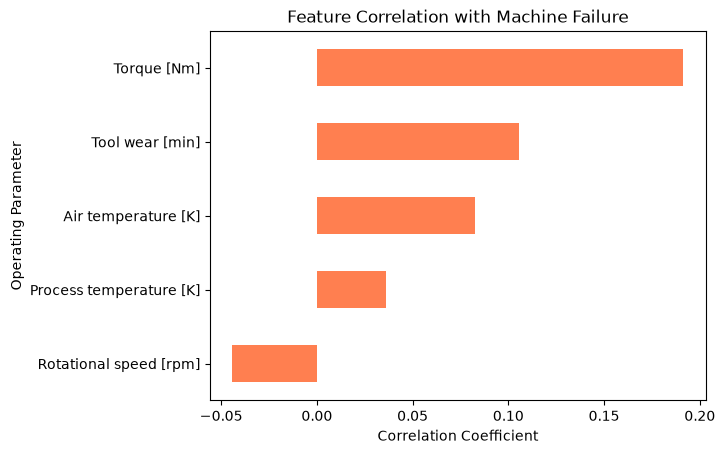

In [25]:
# Plot correlations between operating parameters and machine failure
failure_correlation["Machine failure"].drop("Machine failure").sort_values().plot(
    kind="barh",
    color="coral"
)

plt.title("Feature Correlation with Machine Failure")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Operating Parameter")
plt.show()

## Exploratory Data Analysis Summary

- The dataset contains 10,000 records and 14 columns.
- No missing values or duplicate records were found.
- Machine failures account for 3.39% of observations.
- HDF is the most frequent individual failure type.
- Product type L has the highest failure rate (3.92%).
- Failed machines show higher average torque and tool wear.
- Torque has the strongest positive correlation with machine failure
  among the numerical operating parameters.
- The dataset is highly imbalanced, requiring suitable evaluation metrics.

## Data Preprocessing
Remove unnecessary identifier columns and prepare the
dataset for machine learning model development.

In [26]:
# Remove identifier columns that do not provide useful predictive information
df_ml = df.drop(columns=["UDI", "Product ID"])

# Display the remaining columns
df_ml.columns

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='str')

In [27]:
# Convert product type into numerical columns using one-hot encoding
df_ml = pd.get_dummies(df_ml, columns=["Type"], dtype=int)

# Display the first five rows after encoding
df_ml.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0,1,0
2,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0,1,0
3,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0,1,0
4,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0,1,0


## Feature and Target Separation
Separate independent operating parameters from the target variable.
Exclude failure-type indicators to prevent data leakage.

In [28]:
# Select operating parameters and product type as input features
X = df_ml[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Type_H",
        "Type_L",
        "Type_M"
    ]
]

# Select machine failure as the prediction target
y = df_ml["Machine failure"]

# Display feature and target dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 8)
Target shape: (10000,)


In [29]:
from sklearn.model_selection import train_test_split

# Split data while preserving the original class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training and testing dimensions
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 8)
X_test: (2000, 8)
y_train: (8000,)
y_test: (2000,)


In [30]:
# Check failure distribution in training and testing datasets
print("Training failure distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting failure distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training failure distribution:
Machine failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64

Testing failure distribution:
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create a pipeline with feature scaling and logistic regression
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ))
])

# Train the model using training data
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [32]:
# Predict machine failures using the trained model
y_pred_lr = lr_model.predict(X_test)

# Display the first 10 predictions
print("Predictions:", y_pred_lr[:10])
print("Actual values:", y_test.values[:10])

Predictions: [1 1 1 0 1 1 1 0 0 1]
Actual values: [0 0 0 0 0 0 0 0 0 0]


In [33]:
from sklearn.metrics import classification_report

# Evaluate Logistic Regression predictions
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



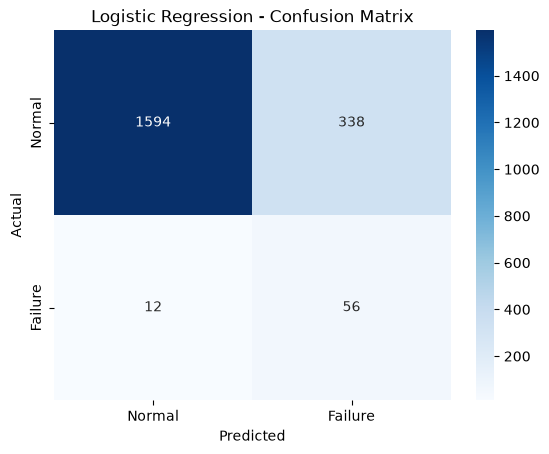

In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Visualize actual vs predicted machine failures
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [35]:
from sklearn.tree import DecisionTreeClassifier

# Create a decision tree with balanced class weights
dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42,
    max_depth=5
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [36]:
# Predict machine failures using the Decision Tree
y_pred_dt = dt_model.predict(X_test)

# Display the first 10 predictions and actual values
print("Predictions:", y_pred_dt[:10])
print("Actual values:", y_test.values[:10])

Predictions: [1 0 1 0 1 0 0 0 0 0]
Actual values: [0 0 0 0 0 0 0 0 0 0]


In [37]:
from sklearn.metrics import classification_report

# Evaluate Decision Tree predictions
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1932
           1       0.31      0.88      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.91      0.71      2000
weighted avg       0.97      0.93      0.95      2000



In [38]:
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest model with balanced class weights
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [39]:
# Predict machine failures using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Display the first 10 predictions and actual values
print("Predictions:", y_pred_rf[:10])
print("Actual values:", y_test.values[:10])

Predictions: [0 0 0 0 0 0 0 0 0 0]
Actual values: [0 0 0 0 0 0 0 0 0 0]


In [40]:
# Evaluate Random Forest predictions
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.70      0.65      0.67        68

    accuracy                           0.98      2000
   macro avg       0.84      0.82      0.83      2000
weighted avg       0.98      0.98      0.98      2000



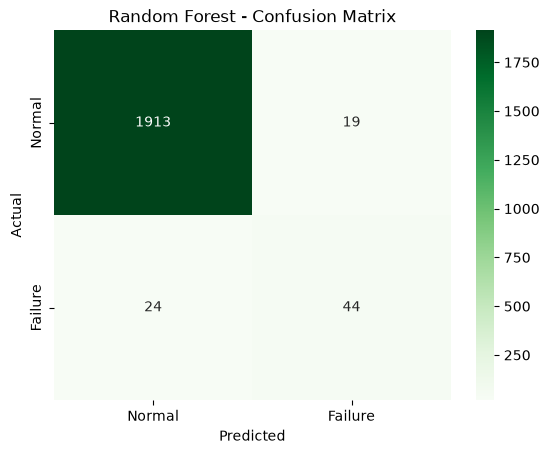

In [41]:
# Calculate the Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Visualize the confusion matrix
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Collect evaluation metrics for all trained models
models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Failure Precision": precision_score(y_test, predictions),
        "Failure Recall": recall_score(y_test, predictions),
        "Failure F1": f1_score(y_test, predictions)
    })

# Display model comparison
results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Failure Precision,Failure Recall,Failure F1
0,Logistic Regression,0.825,0.142,0.824,0.242
1,Decision Tree,0.930,0.311,0.882,0.460
2,Random Forest,0.978,0.698,0.647,0.672


In [43]:
# Extract feature importance from the trained Random Forest model
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
feature_importance

,Feature,Importance
2,Rotational speed [rpm],0.307969
3,Torque [Nm],0.296664
4,Tool wear [min],0.206782
0,Air temperature [K],0.099546
1,Process temperature [K],0.069983
6,Type_L,0.008874
7,Type_M,0.006933
5,Type_H,0.003250


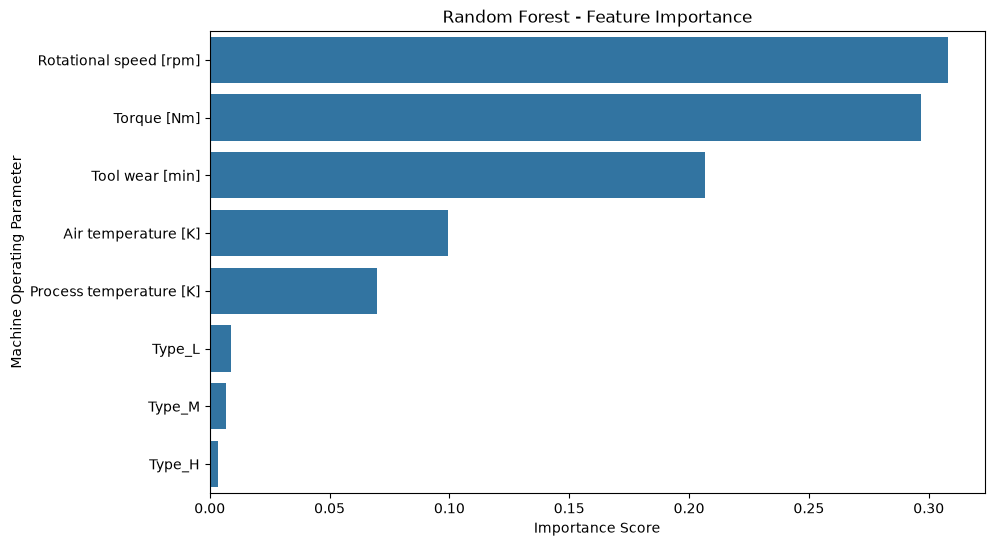

In [44]:
# Plot the importance of machine operating parameters
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Machine Operating Parameter")
plt.show()

In [45]:
# Obtain predicted failure probabilities from Random Forest
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Display the first 10 predicted failure probabilities
print(y_prob_rf[:10])

[0.31 0.   0.14 0.01 0.15 0.   0.01 0.01 0.   0.17]


In [46]:
from sklearn.metrics import classification_report

# Predict failures using a lower probability threshold
y_pred_rf_30 = (y_prob_rf >= 0.30).astype(int)

# Evaluate model performance at threshold 0.30
print(classification_report(y_test, y_pred_rf_30))

              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.50      0.79      0.61        68

    accuracy                           0.97      2000
   macro avg       0.75      0.88      0.80      2000
weighted avg       0.98      0.97      0.97      2000



In [47]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Evaluate Random Forest at different probability thresholds
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    # Convert probabilities into binary predictions
    predictions = (y_prob_rf >= threshold).astype(int)

    # Calculate failure-class evaluation metrics
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

# Display threshold comparison
threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1 Score
0,0.1,0.275,0.926,0.424
1,0.2,0.393,0.868,0.541
2,0.3,0.500,0.794,0.614
3,0.4,0.607,0.750,0.671
4,0.5,0.677,0.647,0.662


In [48]:
# Split training data into model-training and validation datasets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Display dataset sizes
print("Model training data:", X_subtrain.shape)
print("Validation data:", X_val.shape)
print("Final test data:", X_test.shape)

Model training data: (6400, 8)
Validation data: (1600, 8)
Final test data: (2000, 8)


In [49]:
# Train Random Forest using only the model-training subset
rf_model_val = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model_val.fit(X_subtrain, y_subtrain)

print("Random Forest trained on training subset successfully!")

Random Forest trained on training subset successfully!


In [50]:
# Predict failure probabilities for validation data
y_val_prob = rf_model_val.predict_proba(X_val)[:, 1]

# Display the first 10 validation probabilities
print(y_val_prob[:10])

[0.   0.1  0.02 0.05 0.   0.88 0.02 0.   0.   0.  ]


In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Evaluate thresholds using validation predictions only
thresholds = np.arange(0.10, 0.81, 0.05)

validation_results = []

for threshold in thresholds:
    # Convert probabilities into binary predictions
    predictions = (y_val_prob >= threshold).astype(int)

    # Calculate failure-class metrics
    validation_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 Score": f1_score(y_val, predictions, zero_division=0)
    })

# Display validation threshold comparison
validation_df = pd.DataFrame(validation_results)
validation_df.round(3)

,Threshold,Precision,Recall,F1 Score
0,0.10,0.246,0.926,0.389
1,0.15,0.296,0.870,0.441
2,0.20,0.352,0.833,0.495
3,0.25,0.389,0.778,0.519
4,0.30,0.448,0.722,0.553
5,0.35,0.500,0.704,0.585
6,0.40,0.561,0.685,0.617
7,0.45,0.610,0.667,0.637
8,0.50,0.667,0.630,0.648
9,0.55,0.721,0.574,0.639


In [52]:
from sklearn.metrics import classification_report

# Predict failure probabilities on the final test dataset
y_test_prob = rf_model_val.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
y_test_final = (y_test_prob >= 0.50).astype(int)

# Evaluate final model performance
print(classification_report(y_test, y_test_final))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.62      0.66      0.64        68

    accuracy                           0.97      2000
   macro avg       0.81      0.82      0.81      2000
weighted avg       0.98      0.97      0.98      2000



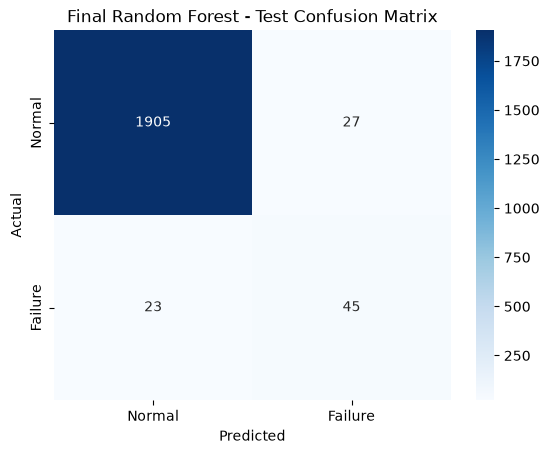

In [53]:
# Calculate the confusion matrix for final test predictions
cm_final = confusion_matrix(y_test, y_test_final)

# Visualize final model performance
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Random Forest - Test Confusion Matrix")
plt.show()

In [54]:
import joblib

# Save the final trained Random Forest model
joblib.dump(rf_model_val, "machine_failure_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [55]:
import joblib

# Load the saved Random Forest model
loaded_model = joblib.load("machine_failure_model.pkl")

# Verify that the model was loaded successfully
print("Saved model loaded successfully!")

Saved model loaded successfully!


In [56]:
# Define a function to predict machine failure
def predict_machine_failure(air_temp, process_temp, rpm, torque, tool_wear, machine_type):

    # Convert machine type into one-hot encoded features
    type_h = 1 if machine_type == "H" else 0
    type_l = 1 if machine_type == "L" else 0
    type_m = 1 if machine_type == "M" else 0

    # Arrange input values in the same feature order used during training
    input_data = pd.DataFrame([[
        air_temp,
        process_temp,
        rpm,
        torque,
        tool_wear,
        type_h,
        type_l,
        type_m
    ]], columns=X.columns)

    # Predict failure probability
    failure_probability = loaded_model.predict_proba(input_data)[0][1]

    # Apply the selected classification threshold
    prediction = 1 if failure_probability >= 0.50 else 0

    # Return prediction details
    return {
        "Machine Status": "Failure" if prediction == 1 else "Normal",
        "Failure Probability": round(failure_probability * 100, 2)
    }

print("Prediction function created successfully!")

Prediction function created successfully!



## Model Deployment and Prediction

The trained Random Forest model is saved and loaded using Joblib.

A prediction function has been developed to accept machine operating parameters and predict whether a machine is likely to fail.

The function returns:
- Predicted machine status (Normal or Failure)
- Predicted failure probability

This demonstrates how the trained model can be reused for predictive maintenance.


In [57]:
# Test the prediction function with sample machine parameters
result = predict_machine_failure(
    air_temp=300.5,
    process_temp=310.5,
    rpm=1500,
    torque=50,
    tool_wear=180,
    machine_type="L"
)

# Display the prediction result
print(result)

{'Machine Status': 'Normal', 'Failure Probability': np.float64(2.0)}



## Project Conclusion

This project developed a machine learning solution for predicting industrial machine failures using the AI4I 2020 Predictive Maintenance Dataset.

Three classification algorithms were evaluated:
- Logistic Regression
- Decision Tree
- Random Forest

Random Forest achieved the strongest overall performance among the evaluated models.

### Final Test Performance
- Accuracy: 97%
- Failure Precision: 62%
- Failure Recall: 66%
- Failure F1-score: 0.64

Feature importance analysis identified rotational speed, torque, and tool wear as the most influential operating parameters.

The model was saved using Joblib and a prediction function was implemented to demonstrate its practical application.

This project demonstrates how machine learning can support predictive maintenance by identifying machines that may require inspection before failure.
